# The Classification Problem

Let $y \in S$ where $S$ is a discrete set of elements (has a specific number of classes). We observe pairs 
$(x, y)$ drawn from some unknown joint distribution $P(X, Y)$ such that:

- $x \in \chi$ is the input (often $\chi =  \mathbb{R}^d$); these are our features
- $y \in S = \{1, 2, \dots, k\}$ with $\left| S\right| = K$ finite; these are our labels, of which we have a finite amount.

The goal of the classification problem is, given a piece of data's features ($x \in \chi$), to classify it into one of the labels ($y \in S$). There are two kinds of classification problems:
- $\left| S\right| = 2$; binary classification problems where something is in one of two categories
- $\left| S\right| > 2$; multi-class classification probelems where something is in one of many categories

For now, we will focus on binary classification problems. These are approached using Logistic Regression.

# Logistic Regression

Logistic Regression grows on the fundamentals introduced in the Linear Regression chapter by applying it to the classification problem. Logistic Regression works by assigning a probability of an event occuring given certain input features. Depending on the probability of an event, something is classified into one of two classes; it aims to solve binary classification problems.

Let's go through a basic example that we can refine later. Assume we want to determine if a student passes a test given a certain number of hours studied. 

- For student A who studied 5h, our model determines there is a 30% chance of passing, so it predicts that the student does not pass the test (label of 0)

- For student B who studied 15h, our model determines there is a 90% chance of passing, so it predicts that the student does pass the test (label of 1)

The is an example of a binary classification, as there are only two possible outcomes or classes: passing the test, or not passing the test. With this example completed, it is now fit the begin the basics of the model.

In [2]:
#%pip install numpy # you can comment these out once you have installed them
#%pip install pandas
#%pip install matplotlib

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. The Sigmoid
We already have a method to predict an outcome given input features, but there is a problem: the range. The range of linear regression is that of a line, and that is (for one that is not completely horizontal, like our model typically produces) all real numbers $(-\infty, \infty)$. By contrast, we want a probability represented on the range $[0, 1]$ or $(0, 1)$. So what we need is a function that can convert our line's outputs into a range which we can interpret as probability.

The sigmoid (also called a logistic function) is a function that converts and real number to a value strictly between 0 and 1 ($\sigma: \mathbb{R} \rightarrow (0, 1)$):

$$\sigma(z) = \frac{1}{1 + exp(-z)}$$

Visually, it appears as a **nonlinear function** that looks like so:

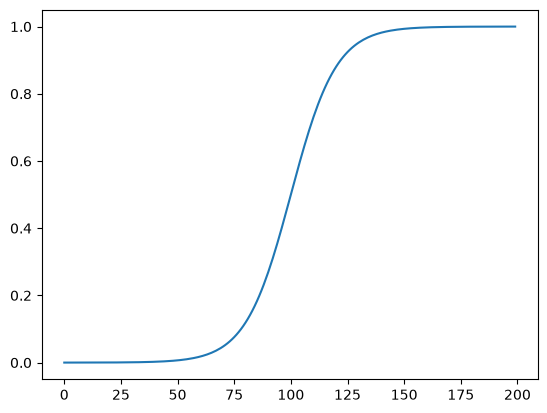

In [4]:
# real numbers
X = np.array([x/10 for x in range(-100, 100)])
# convert to sigmoid
sigmoid_X = 1 / (1 + np.exp(-X))
# plot sigmoid
plt.plot(sigmoid_X)

## 2. Log Odds

This section seems like a bit of a detour but I promise it goes somewhere.

Recall that the sigmoid is giving us a probability. This means that $\sigma(z) = \pi$ where $\pi$ is some probability. We can set our sigmoid function equal to $\pi$, and solve for the value of z.

$$\pi = \frac{1}{1 + e^{-z}}$$

We can then take the reciprocal of both sides:

$$\frac{1}{\pi} = 1 + e^{-z}$$

Isolate $e^{-z}$:

$$\frac{1}{\pi} - 1 = e^{-z}$$

Combine the left side into one fraction:

$$\frac{1 - \pi}{\pi} = e^{-z}$$

You can then take the reciprocals of both sides, and cross multiply to convert the $-z$ to a $z$:

$$\frac{\pi}{1 - \pi} = e^{z}$$

Take the $\ln$ of both sides to isolate for z:

$$z = \ln \frac{\pi}{1 - \pi}$$

In ML/Stats, the convention of $\log$ is to treat it as if it is $\ln$, so conventionally this can be written as:

$$z = \log \frac{\pi}{1 - \pi}$$

The $\frac{\pi}{1 - \pi}$ is the formula to convert a probability into odds. By taking the $\log$ of this value, we then get the log odds. This explains the connection between our linear function, which will produce an output in log-odds form (log-odds are on the range $(-\infty, \infty)$), which we will then convert into a probability using the sigmoid.

## 3. The Bernoulli Distribution

Previously, we used Sum of Squared Error (SSE) as our Loss Function. This was obtained by performing maximum likelihood estimation on a normal distribution, and subbing in our model for the value of $\mu$. Recall: we used a normal distribution because our target was a continuous variable, and noise from many small independent effects tends to be normally distributed (Central Limit Theorem).

However, in this scenario, we only have 2 possible discrete outcomes, meaning that we should use a different distribution instead of a normal one. Specifically, we will use a Bernoulli Distribution, a version of a Binomial Distribution. A typical Binomial Distribution finds the number of successes ($k$) given $n$ trials, and follows the formula:

$$P(K=k) = \binom{n}{k} \pi^k (1-\pi)^{n-k}$$

Where $\pi$ is the probability of an outcome, $1-\pi$ is the probability of the opposite outcome, and $n-k$ is the number of failures. However, because each data point represents one trial and because $k \in \{0, 1\}$ (it is either 1 success or 0 success), and $\binom{1}{0} = \binom{1}{1} = 1$, we can represent both success and failure using the same distribution, as we are only focused on one outcome (either occurs or does not occur):

$$P(K=k) = \pi^k (1-\pi)^{1-k}$$

### The Maximum Likelihood of a Bernoulli Distribution

The goal of our model is to find the parameters $\theta$ that make the observed labels as likely as possible. In other words, we want the predicted probability $\pi_n$ to be close to 1 when $y_n = 1$, and close to 0 when $y_n = 0$.

With this context, the probability of a single label is a Bernoulli:

$$p(y_n \mid x_n, \theta) = \sigma(f(x_n; \theta))^{\,y_n}(1 - \sigma(f(x_n; \theta)))^{1 - y_n}$$

Since the data points are identically and independently distributed, the likelihood of the whole dataset is the product over all data points:

$$p(\mathcal{D} \mid \theta) = \prod_{n=1}^N p(y_n \mid x_n, \theta)$$

However, multiplying many probabilities causes data loss and overflow, so we take the log:

$$\log p(\mathcal{D} \mid \theta) = \log \prod_{n=1}^N p(y_n \mid x_n, \theta)$$

Logarithms turn products into sums:

$$\log p(\mathcal{D} \mid \theta) = \sum_{n=1}^N \log p(y_n \mid x_n, \theta)$$

Substituting the Bernoulli formula:

$$\log p(\mathcal{D} \mid \theta) = \sum_{n=1}^N \log (\sigma(f(x_n; \theta))^{\,y_n}(1 - \sigma(f(x_n; \theta)))^{1 - y_n})$$

Expand the log of a sum into the logs of 2 sums:

$$\log p(\mathcal{D} \mid \theta) = \sum_{n=1}^N \Big(\log\Big(\sigma(f(x_n; \theta))^{\,y_n}\Big) + \log\Big(\big(1 - \sigma(f(x_n; \theta))\big)^{1 - y_n}\Big)\Big)$$

Use the log power rule to bring down the exponent:

$$\log p(\mathcal{D} \mid \theta) = \sum_{n=1}^N y_n \Big(\log \sigma(f(x_n; \theta)) + (1 - y_n)\log\big(1 - \sigma(f(x_n; \theta))\big)\Big)$$

In order to optimize for $\theta$, we can take the gradient (gradient of a sum is the sum of the gradients):

$$\nabla_\theta \log p(\mathcal{D} \mid \theta) = \sum_{n=1}^N \Big[ \nabla_\theta\, y_n \log \sigma(f(x_n; \theta)) + \nabla_\theta\, (1 - y_n)\log\big(1 - \sigma(f(x_n; \theta))\big) \Big]$$

We then perform chain rule on the first term (**NOTE:** $\nabla_\theta f(x_n; \theta) = \nabla_\theta \theta^\top \Phi(x_n) = \text{Whatever the feature matrix is} = \Phi(x_n)$ or $\hat{x}_n$, here we will use $\Phi(x_n)$):

$$\nabla_\theta \log p(\mathcal{D} \mid \theta) = \sum_{n=1}^N \Big[ y_n \cdot \frac{1}{\sigma(f(x_n; \theta))} \cdot \sigma(f(x_n; \theta))\big(1 - \sigma(f(x_n; \theta))\big) \cdot \Phi(x_n) + \nabla_\theta\, (1 - y_n)\log\big(1 - \sigma(f(x_n; \theta))\big) \Big]$$

We can cancel out the $\sigma(f(x_n; \theta))$:

$$\nabla_\theta \log p(\mathcal{D} \mid \theta) = \sum_{n=1}^N \Big[ y_n\big(1 - \sigma(f(x_n; \theta))\big)\Phi(x_n) + \nabla_\theta\, (1 - y_n)\log\big(1 - \sigma(f(x_n; \theta))\big) \Big]$$

We then perform chain rule on the second term:

$$\nabla_\theta \log p(\mathcal{D} \mid \theta) = \sum_{n=1}^N \Big[ y_n\big(1 - \sigma(f(x_n; \theta))\big)\Phi(x_n) + (1 - y_n) \cdot \frac{1}{1 - \sigma(f(x_n; \theta))} \cdot \Big(-\sigma(f(x_n; \theta))\big(1 - \sigma(f(x_n; \theta))\big)\Big) \cdot \Phi(x_n) \Big]$$

We can then cancel out the $1 - \sigma(f(x_n; \theta)$:

$$\nabla_\theta \log p(\mathcal{D} \mid \theta) = \sum_{n=1}^N \Big[ y_n\big(1 - \sigma(f(x_n; \theta))\big)\Phi(x_n) - (1 - y_n)\,\sigma(f(x_n; \theta))\,\Phi(x_n) \Big]$$

We can then factor out the $\Phi(x)$:

$$\nabla_\theta \log p(\mathcal{D} \mid \theta) = \sum_{n=1}^N \Big[ y_n\big(1 - \sigma(f(x_n; \theta))\big) - (1 - y_n)\,\sigma(f(x_n; \theta)) \Big]\Phi(x_n)$$

Distribute the $y_n$:

$$\nabla_\theta \log p(\mathcal{D} \mid \theta) = \sum_{n=1}^N \Big[ y_n - y_n\sigma(f(x_n; \theta)) - \sigma(f(x_n; \theta)) + y_n\sigma(f(x_n; \theta)) \Big]\Phi(x_n)$$

And cancel out the $y_n\sigma(f(x_n; \theta))$ terms:

$$\nabla_\theta \log p(\mathcal{D} \mid \theta) = \sum_{n=1}^N \big(y_n - \sigma(f(x_n; \theta))\big)\Phi(x_n)$$

However, there is a problem. Unlike in linear regression, where we could solve for the value of $\theta$ directly by setting the gradient to $0$, there is no way we can solve the equation here, because the $\theta$ term inside of $f(x_n; \theta) = \theta^\top \Phi(x_n)$ is trapped inside of the sigmoid function, which is nonlinear and does not provide a solution. As a result, we will use gradient ascent to solve for the optimized values for $\theta$.

## 4. Converting a Probability to a Label

Suppose we have finished training our model, and have found $\theta^*$ such that we have the optimal model weights. We now have a linear model whose outcome is a log odds value we can convert into a probability, but we now need to convert that probability into a label (either $0$ or $1$).

Typically, we use a threshhold value ($\tau$), to convert our probability into a label. For instance, if $\tau = 0.5$, then every time we have a probability below $0.5$, we can map that to a $0$. Whenever we have a probability above $0.5$, we can map that to a $1$. Increasing the value of $\tau$ allows us to be more strict and have our model only classify data with a label of $1$ in cases with a higher probability. We will focus on how to determine the best $\tau$ in the next section.

## 5.1 Judging a model Using Accuracy

Given $\mathcal{D}=\{x_m, y_m\}^M_{m=1}$, we want to compare each label $y_m$ to our predicted model output $\hat{y}_m$. We can do this using the accuracy metric, which expalins numerically how good our model is at getting the correct answer. The formula for accuracy is:

$$\text{Accuracy} = \frac{1}{M}\sum_{m=1}^M \mathbf{1}[\hat{y}_m - y_m]$$

**NOTE: The $\mathbf{1}$ is an indicator function. This means the output is $1$ if the condition is True and $0$ if the condition is False.**

Accuracy is calculated by taking the sum ($\sum_{m=1}^M$) of the number of correct predictions made by the model $\mathbf{1}[\hat{y}_m - y_m]$, and dividing by the number of data points ($\frac{1}{M}$).

With **all** of this info understood now, we can go through an example. First, let's generate some data:

In [5]:
rng = np.random.default_rng(0)
# size of data set
n = 100

# generate 2 model features
f1 = rng.uniform(-3, 3, n)
f2 = rng.uniform(-3, 3, n)
# feature matrix with a bias column
X = np.column_stack((f1, f2))
X_hat = np.column_stack((X, np.ones(n)))

# true weights of model
# NOTE: we can also apply polynomial regression to this data, but for simplicity I will not
# The sigmoid does not care what goes inside, so long as it is a linear function.
theta_true = np.array([0.5, 2.0, -1.5])

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# convert log odds generated by model into true probabilities
p = sigmoid(X_hat @ theta_true)

# label using bernoulli distribution (binomial with 1 trial) for each probability
y = rng.binomial(1, p)

Split this into training and testing data:

In [6]:
# randomize the features and labels
indices = rng.permutation(len(y))
X, y = X[indices], y[indices]

# training amount
train_amt = 0.8
train_amt_ind = int(len(y) * train_amt)

# keep 80% for training
X_train = X[:train_amt_ind]
y_train = y[:train_amt_ind]

# leave 20% for testing
X_test = X[train_amt_ind:]
y_test = y[train_amt_ind:]

We will also define a predict function:

In [7]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def logistic_predict(X, theta):
    return sigmoid(X @ theta)

And also define an accuracy function:

In [8]:
def logistic_classify(X, theta, threshold=0.5):
    return (logistic_predict(X, theta) >= threshold).astype(int)

def logistic_accuracy(X, theta, y_true):
    return np.mean(logistic_classify(X, theta) == y_true)

We can now perform gradient ascent to optimize for $\theta$:

In [9]:
# initial model weights
theta = np.ones(X.shape[1])

# step size
alpha = 0.01

# number of iterations
T = 100

for i in range(T):
    # this does weight calculation and summation in one big step
    grad_theta = (y_train - logistic_predict(X_train, theta)) @ X_train
    theta = theta + grad_theta * alpha

And then we can check the mode's accuracy:

In [10]:
print(f'Training accuracy: {logistic_accuracy(X_train, theta, y_train)}')
print(f'Testing accuracy: {logistic_accuracy(X_test, theta, y_test)}')

Training accuracy: 0.8375
Testing accuracy: 0.85


## 5.2 Juding a Model Using a Confusion Matrix and Associated Metrics

Suppose we have a model that trains on imbalanced data. For instance, there are 99 data entries with label 0, and 1 entry with label 1. A model trained on this data would always classify something as a label 0, because it never (or very rarely, depending on train-test split) sees a label 1. However, because all other data is of label 0, a model scored using only accuracy would get a score of $99\%$. 

A confusion matrix and its associated metrics, give us other ways to judge our model, outside of accuracy. It follows the general format:

$$
\begin{array}{c|cc}
 & \hat{y} = 0 & \hat{y} = 1 \\
\hline
y = 0 & \text{TN} & \text{FP} \\
y = 1 & \text{FN} & \text{TP}
\end{array}
$$

**Where:** 
- TN = True Negative
- FN = False Negative
- TP = True Positive
- FP = False Positive.

We can then use the values in our confusion matrix to determine other ways to score our model.

$\text{Accuracy} = \frac{TP + TN}{TP + FP + TN + FN}$ tells us how often the model is correct overall, across both classes.

$\text{Precision} = \frac{TP}{TP + FP}$ tells us how many of the points the model predicted as positive are actually positive. High precision means few false alarms.

$\text{Recall} = \frac{TP}{TP + FN}$ tells us how many of the actual positives the model successfully found. High recall means few missed positives.

$\text{Specificity} = \frac{TN}{TN + FP}$ tells us how many of the actual negatives the model correctly identified as negative. It is the equivalent of recall for the negative class.

$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$ tells us how well the model balances precision and recall. Because it is their harmonic mean, it is only high when both are high.

Let's now apply this to our example above. Our confusion matrix is:

$$
\begin{array}{c|cc}
 & \hat{y} = 0 & \hat{y} = 1 \\
\hline
y = 0 & 99 & 0 \\
y = 1 & 1 & 0
\end{array}
$$

$\text{Accuracy} = \frac{0 + 99}{0 + 0 + 99 + 1} = \frac{99}{100}=0.99$

$\text{Precision} = \frac{0}{0 + 0} = \text{undefined, but treat it as } 0$

$\text{Recall} = \frac{0}{0 + 1} = 0$ 

$\text{Specificity} = \frac{99}{99 + 0} = 1$

$\text{F1-Score} = 2 \times \frac{0 \times 0}{0 + 0} = \text{undefined, but treat it as } 0$

Since the model predicts 0 for everything, it scores 99% accuracy and perfect specificity. However, it never finds the one positive case, so recall and F1 are both 0. If that positive were a fraud case or a disease, the model would be useless. 

We will learn how to deal with the data from an example like this so that our model can actually be used to predict data later on.

Let's use these metrics on the model we have just trained:

In [11]:
model_prediction = logistic_classify(X_test, theta)

TP = np.sum((model_prediction == y_test) & (model_prediction == 1))
TN = np.sum((model_prediction == y_test) & (model_prediction == 0))
FP = np.sum((model_prediction != y_test) & (model_prediction == 1))
FN = np.sum((model_prediction != y_test) & (model_prediction == 0))

precision = TP / (FP + TP)
recall = TP / (TP + FN)
specificity = TN / (FN + TN)
f1 = 2 * (precision * recall) / (precision + recall)

print(f'The model has a precision score on the test data of: {precision:.2f}')
print(f'The model has a recall score on the test data of: {recall:.2f}')
print(f'The model has a specificity score on the test data of: {specificity:.2f}')
print(f'The model has an f1 score on the test data of: {f1:.2f}')

The model has a precision score on the test data of: 0.83
The model has a recall score on the test data of: 0.91
The model has a specificity score on the test data of: 0.88
The model has an f1 score on the test data of: 0.87


## 6. The Effect of Changing the Threshold $(\tau)$
Changing the value of $\tau$ can change the values of precision and recall.

A higher $\tau$ produces a model that is very confident. This means fewer false positives, but also more false negatives, leading to higher precision with lower recall (accurate model that is scared to classify something as true).

A lower $\tau$ produces a model that predicts liberally. This means more false positives, but also more true positives too, leading to lower precision with higher recall (model that will classify more things as true, but will classify things that should be false as true).

This value of $\tau$ can vary based on the situation. For instance for spam filtering you may want a high $\tau$, where you classify emails as spam with high confidence. This might let some spam in, but will reduce the risk of missing an actually important email. By constrast for cancer screening, you may want a lower $\tau$, where you may scare some people into thinking they actually do have cancer, when in reality don't, but missing a positive cancer diagnosis is costly.

### The Precision-Recall Curve (PRC)

The Precision-Recall Curve (PRC) maps the relationship between precision and recall. It graphs how the current model's precision and recall scores change across all possible values for $\tau$, from lowest value of $\tau$ to highest. 

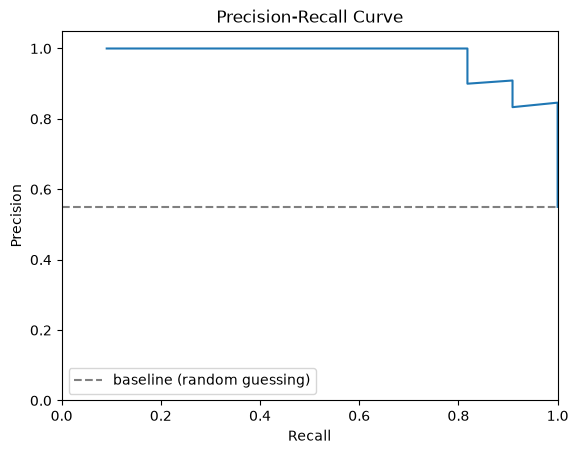

In [12]:
# possible values of tau in 0.01 increments
thresholds = np.linspace(0, 1, 101)
# store precisions and recalls to graph
precisions, recalls = [], []

for tau in thresholds:
    # determine model predictions
    y_pred = logistic_classify(X_test, theta, tau)

    # calculate needed statstics for precision and recall
    TP = np.sum((y_pred == 1) & (y_test == 1))
    FP = np.sum((y_pred == 1) & (y_test == 0))
    FN = np.sum((y_pred == 0) & (y_test == 1))

    # don't include division by 0 error cases
    if TP + FP == 0: continue
    # add up precisions and recalls
    precisions.append(TP / (TP + FP))
    recalls.append(TP / (TP + FN))

plt.plot(recalls, precisions)
plt.axhline(y_test.mean(), linestyle='--', color='gray', label='baseline (random guessing)')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend()
plt.show()

### Area Under Precision Recall Curve (AUPRC)

The Area Under a Precision Recall Curve (AUPRC) is calculated as the difference between recalls, multiplied by the precision; it is Reimann sum used to calculate the area of the curve, where the width of a sliver of area is the difference between recalls. Its formula is written as:

$$\text{AUPRC} = \sum_k (R_k - R_{k-1})\, P_k$$

Where $R_k$ is a the current recall value, $R_{k-1}$ is the previous recall value, and $P_k$ is the precision value. An AUPRC with a value of 1 means that there exists a $\tau$ that achieves perfect precision and recall.

For the example previously, we can calculate the AUPRC:

In [13]:
# graph so recall is increasing
P = np.array(precisions)[::-1]
R = np.array(recalls)[::-1]

# 0 + previous recalls
R_prev = np.concatenate(([0], R[:-1]))

# calculate AUPRC
auprc = np.sum((R - R_prev) * P)
print(f'Testing data AUPRC: {auprc:.3f}')

Testing data AUPRC: 0.978


## 7. Imbalanced Classes

## 8. Non-linear boundaries

## 9. Separable data and regularization

# Mutliclass Classification

Multiclass classification uses a different approach compared to Logistic Regression in order to categorize data. To recall, the classification problems is where $y \in S$ and $S$ is a discrete set of elements (has a specific number of classes). We observe pairs $(x, y)$ drawn from some unknown joint distribution $P(X, Y)$ such that:

- $x \in \chi$ is the input (often $\chi =  \mathbb{R}^d$); these are our features
- $y \in S = \{1, 2, \dots, k\}$ with $\left| S\right| = K$ finite; these are our labels, of which we have a finite amount.

When $\left|S\right| = 2$, we used logistic regression.

However, when $\left|S\right| > 2$, we use multiclass classification.

## 1. Categorical Variables

Previously, we represented binary variables as $y \in \{0, 1\}$, but since we now have $K$ possible categories where $K > 2$, we can instead represent this as $y \in \{0, 1, \dots, K-1\}$. To represent multiple classes easily, we use **one-hot vectors** to encode categories as vectors. Let's look at the following example:

$\text{Let } y \in \{0, 1, 2, 3\}$$

$\text{When } y = 2 \implies y = [0, 0, 1, 0]^{\top}$; the category $2$ has a $1$ at the index of the $2$.

$\text{When } y = 0 \implies y = [1, 0, 0, 0]^{\top}$; the category $0$ has a $1$ at the index of the $0$.



## 2. The Softmax Function

The softmax function takes in $K$ real numbers (logits) $\boldsymbol{z} = [z_0, \dots, z_{K-1}]$ and outputs a vector with $K$ entries, where each entry is the probability for a given label:

$$\text{softmax}(\boldsymbol{z})_k = \frac{\exp(z_k)}{\sum_{j=0}^{K-1} \exp(z_j)}$$

It exponentiates each logit to make it positive, then divides by the total so the entries sum to $1$. Each entry is strictly between $0$ and $1$, and a larger logit always gets a larger probability.

For instance, assume $K = 3$ and $z = [1, 0, -1]$.

1. Exponentiate each logit: $e^{1} = 2.718$, $e^{0} = 1$, $e^{-1} = 0.368$.
2. Sum them: $2.718 + 1 + 0.368 = 4.086$.
3. Divide each by the sum:

$$\text{softmax}(\boldsymbol{z}) = \left[\frac{2.718}{4.086}, \frac{1}{4.086}, \frac{0.368}{4.086}\right] = [0.665, 0.245, 0.090]$$

The entries sum to $1$, the largest logit gets the largest probability, and the negative logit still gets a positive probability. We will represent this vector with the label $\pi$ ("the probability vector"), which gives the probability for each label.

## 3. The Categorical Distribution

The categorical distribution describes a variable $y$ that takes one of $K$ possible values. If the Bernoulli distribution represents a binary outcome like flipping a coin, the categorical distribution covers a $K$-sided die roll.

The distribution has a parameter $\pi$, a vector whose $y$-th entry is the probability of category $y$. Formally, $P(y \mid \pi) = \pi_y$ for $y \in \{0, 1, \dots, K-1\}$. For example, if $K=3$, $\pi=[0.2, 0.5, 0.3]$, and $y \in \{0, 1, 2\}$:

$$P(y = 0) = 0.2$$
$$P(y = 1) = 0.5$$
$$P(y = 2) = 0.3$$

**NOTE: the probabilities in $\pi$ must be valid probabilities (between 0 and 1) which sum up to $1$.**

We can write this distribution compactly as:

$$P(y \mid \pi) = \prod_{k=0}^{K-1}\pi_k^{\mathbf{1}[y = k]}$$

Here $\mathbf{1}[y = k]$ is $1$ when $y = k$ and $0$ otherwise. Since $x^0 = 1$, every factor except the one for $k = y$ equals $1$, so the product reduces to $\pi_y$.

### The Maximum Likelihood of the Categorical Distribution

The categorical PMF $P(y \mid \pi)$ can be read in two ways. With $\pi$ fixed and $y$ varying, it gives the probability of each possible outcome. With $y$ fixed at an observed value and $\pi$ varying, it is the **likelihood**: a measure of how well a particular $\pi$ explains what we observed. The formula is the same; only the question changes.

Now suppose we observe a dataset $\mathcal{D} = \{y_1, \dots, y_N\}$ of $N$ independent observations.

**Likelihood.** Because the observations are independent, the probability of the whole dataset is the product of the probabilities of each observation:

$$P(\mathcal{D} \mid \pi) = P(y_1, \dots, y_N \mid \pi) = \prod_{n=1}^{N} P(y_n \mid \pi)$$

Substituting the compact form of the categorical PMF for each $P(y_n \mid \pi)$ gives:

$$P(\mathcal{D} \mid \pi) = \prod_{n=1}^{N} \prod_{k=0}^{K-1} \pi_k^{\mathbf{1}[y_n = k]}$$

**Log-likelihood.** Products are awkward to work with, so we take the log:

$$\log P(\mathcal{D} \mid \pi) = \log \prod_{n=1}^{N} \prod_{k=0}^{K-1} \pi_k^{\mathbf{1}[y_n = k]}$$

Since the log of a product is a sum, the outer product becomes a sum:

$$\log P(\mathcal{D} \mid \pi) = \sum_{n=1}^{N} \log \prod_{k=0}^{K-1} \pi_k^{\mathbf{1}[y_n = k]}$$

The same rule turns the inner product into a sum:

$$\log P(\mathcal{D} \mid \pi) = \sum_{n=1}^{N} \sum_{k=0}^{K-1} \log \pi_k^{\mathbf{1}[y_n = k]}$$

Using $\log a^b = b \log a$, we bring the exponent down in front:

$$\log P(\mathcal{D} \mid \pi) = \sum_{n=1}^{N} \sum_{k=0}^{K-1} \mathbf{1}[y_n = k] \log \pi_k$$

So the log-likelihood is simply the sum of the log-probabilities that $\pi$ assigns to the observed outcomes. The closer it is to $0$, the more probability $\pi$ places on what actually happened, and the better it fits the data.

Let's go through an example calculating Log Likelihood. Let $K = 3$ with $\pi = [0.2, 0.5, 0.3]$, and suppose we have the labels $y = [1, 2, 1]$, where $y \in \{0, 1, 2\}$.

For each observation, the inner sum has one term per class, and the indicators zero out all but the observed class:

$$n = 1: \quad 0 \cdot \log 0.2 + 1 \cdot \log 0.5 + 0 \cdot \log 0.3 = \log 0.5 = -0.693$$
$$n = 2: \quad 0 \cdot \log 0.2 + 0 \cdot \log 0.5 + 1 \cdot \log 0.3 = \log 0.3 = -1.204$$
$$n = 3: \quad 0 \cdot \log 0.2 + 1 \cdot \log 0.5 + 0 \cdot \log 0.3 = \log 0.5 = -0.693$$

Adding over the three observations:

$$\log P(\mathcal{D} \mid \pi) = -0.693 - 1.204 - 0.693 = -2.590$$

As a check, this matches the log of the likelihood: $\log 0.075 = -2.590$.

Now, in order to find the optimal model weights, we will substitute our value of $\pi$ with how it is calculated: $\pi = \text{softmax}(f(x; W))$, and solve for the gradient with respect to $W$.

**ToDo: Actually solve for the gradient**

This gives us our final answer of:

$$\nabla_{\boldsymbol{W}} \log P(\mathcal{D} \mid \boldsymbol{W}) = \sum_{n=1}^{N} \big(\text{onehot}(y_n) - \boldsymbol{\pi}_n\big)\,\phi(\boldsymbol{x}_n)^\top$$

## 4. Model Structure

A Multiclass Classification model works by effectively taking 3 linear models' weights, stacking them on top of one another as rows, converting their outputs (which are logits) to probabilities, and then using the softmax function to convert the 3 probabilities into a vector with each label's probability as the $n$-th entry.

Assume we have a dataset $\mathcal{D} = \{(\boldsymbol{x}_n, y_n)\}_{n=1}^N$ with $y_n \in \{0, 1, \dots, K-1\}$. Our model is:

$$f(\boldsymbol{x}; \boldsymbol{\theta}) = f(\boldsymbol{x}; \boldsymbol{W}) = \boldsymbol{W}\hat{x}_n,$$

where $\phi(\boldsymbol{x}) \in \mathbb{R}^D$ is the feature vector of input $\boldsymbol{x}$, and $\boldsymbol{W} \in \mathbb{R}^{K \times D}$ is a weight matrix whose $k$-th row is the linear model for class $k$ (each row in the matrix is a linear model which will produce a logit). The output $f(\boldsymbol{x}; \boldsymbol{W}) \in \mathbb{R}^K$ is a vector of $K$ logits, one score per class (we will get one logit per linear model).

We will then use the softmax function on our vector of logits to convert each logit into a probability. We will then perform gradient descent on our model to optimize for $W$. This process is more complicated than our previous models, so we will go through an example to understand it. First, we will generate our artificial data. Do not worry if you do not fully understand this step:

In [14]:
import numpy as np

rng = np.random.default_rng(0)
# number of data points
n = 9000
# number of classes
K = 3

# three features
X = rng.uniform(-3, 3, (n, 3))
X_hat = np.column_stack((np.ones(n), X))       # shape (80, 4)

# true weights: one row per class
# columns: [intercept, x1, x2, x3]
W_true = np.array([[ 0.0,  2.0,  0.0, -1.0],   # class 0
                   [ 0.5, -2.0,  2.0,  0.0],   # class 1
                   [-0.5,  0.0, -2.0,  1.5]])  # class 2
                                               # shape (3, 4)

# define softmax function
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)
    expZ = np.exp(Z)
    return expZ / expZ.sum(axis=1, keepdims=True)

P = softmax(X_hat @ W_true.T)
y = np.array([rng.choice(K, p=row) for row in P])

Y = np.eye(K)[y]

# --- noise 2: feature noise ---
# the labels came from the clean features, but the model only sees noisy ones
noise_std = 0.5
X_noisy = X + rng.normal(0, noise_std, size=X.shape)
X_hat = np.column_stack((np.ones(n), X_noisy))  # use this for training and testing

We will then split our data into training and testing data

In [15]:
# shuffle row order so the split is random
indices = rng.permutation(n)

# index where 80% of data cuts off
train_amt = 0.8
train_amt_ind = int(n * train_amt)

train_idx = indices[:train_amt_ind]
test_idx = indices[train_amt_ind:]

# keep 80% for training
X_train = X_hat[train_idx]          # (64, 4)
Y_train = Y[train_idx]              # (64, 3), one-hot, for the gradient
y_train = y[train_idx]              # (64,), class numbers, for accuracy

# leave 20% for testing
X_test = X_hat[test_idx]            # (16, 4)
Y_test = Y[test_idx]                # (16, 3)
y_test = y[test_idx]                # (16,)

We will then initialize our model weights in a matrix. The number of rows is the number of classes, and the number of columns is $K + 1$, where $K$ is the number of features.

In [20]:
W = np.zeros((K, X.shape[1] + 1))

In [17]:
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)
    expZ = np.exp(Z)
    return expZ / expZ.sum(axis=1, keepdims=True)

def softmax_predict(X, W):
    return softmax(X @ W.T)

In [18]:
# step size
alpha = 0.01

# number of iterations
T = 1000

for i in range(T):
    # this does weight calculation and summation in one step
    grad_W = (Y_train - softmax_predict(X_train, W)).T @ X_train
    W = W + alpha * grad_W

In [19]:
# probability of each class for each test point
P_test = softmax_predict(X_test, W)                 # (16, 4) @ (4, 3) → (16, 3)

# predicted class = the one with the highest probability
y_pred = np.argmax(P_test, axis=1)             # (16,), values 0, 1 or 2

# accuracy: fraction of predictions that match the true labels
accuracy = np.mean(y_pred == y_test)
print(f'Test accuracy: {accuracy:.2f}')

Test accuracy: 0.78
